In [44]:
import pandas as pd
import numpy as np
from pathlib import Path
from scripts import *

p = Path('genai_results/tests')
dfs = {}
for f in p.iterdir():
    dfs[str(f)] = pd.read_csv(f, nrows=9)

In [45]:
qwen_7b_cpu = prepare_benchmark(dfs['genai_results/tests/qwen_cpu.csv'])
qwen_7b_gpu = prepare_benchmark(dfs['genai_results/tests/qwen_gpu.csv'])
qwen_7b_npu = prepare_benchmark(dfs['genai_results/tests/qwen_npu.csv'])

qwen_7b = {
    "cpu": qwen_7b_cpu,
    "gpu": qwen_7b_gpu,
    "npu": qwen_7b_npu,
}

data_7b = pd.concat(
    [prepare_benchmark(df).assign(source=name)
     for name, df in qwen_7b.items()],
    ignore_index=True,
)


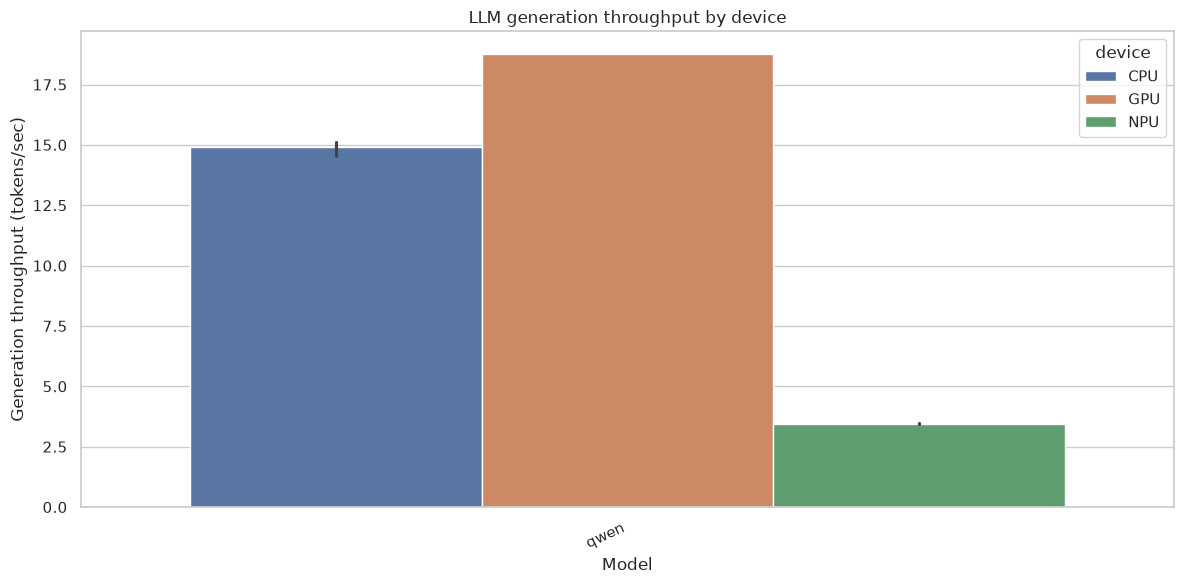

In [46]:
plot_generation_throughput(data_7b)

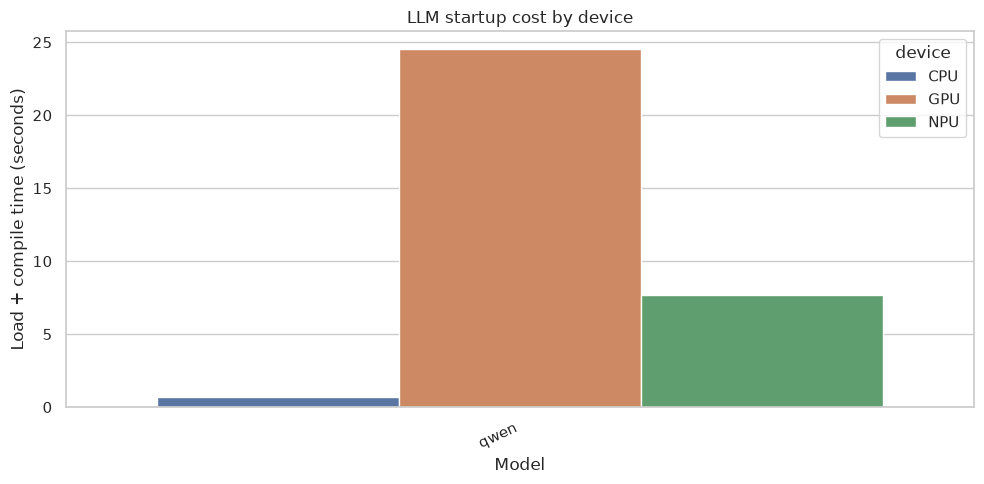

In [47]:
plot_startup_cost(qwen_7b)

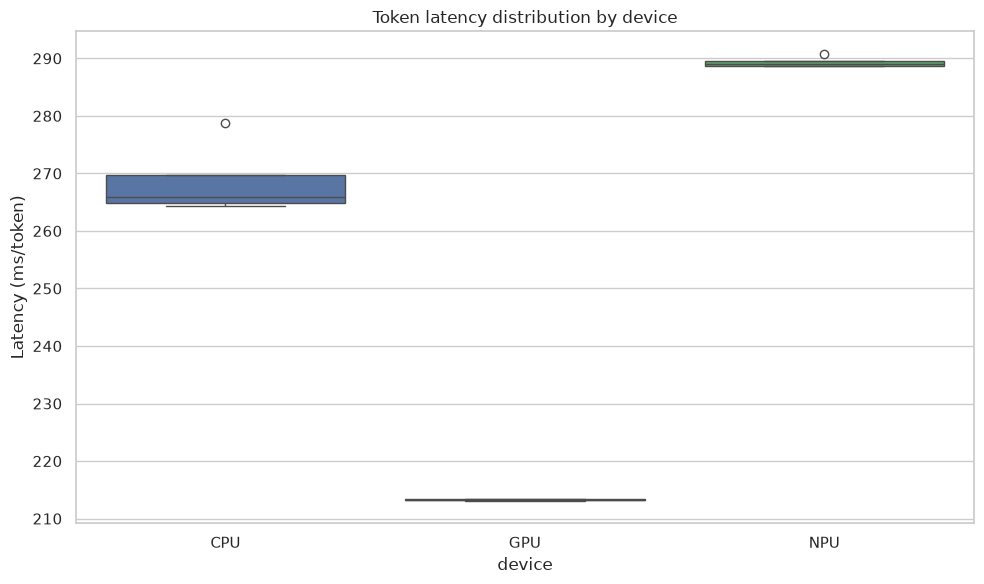

In [48]:
plot_latency(data_7b)

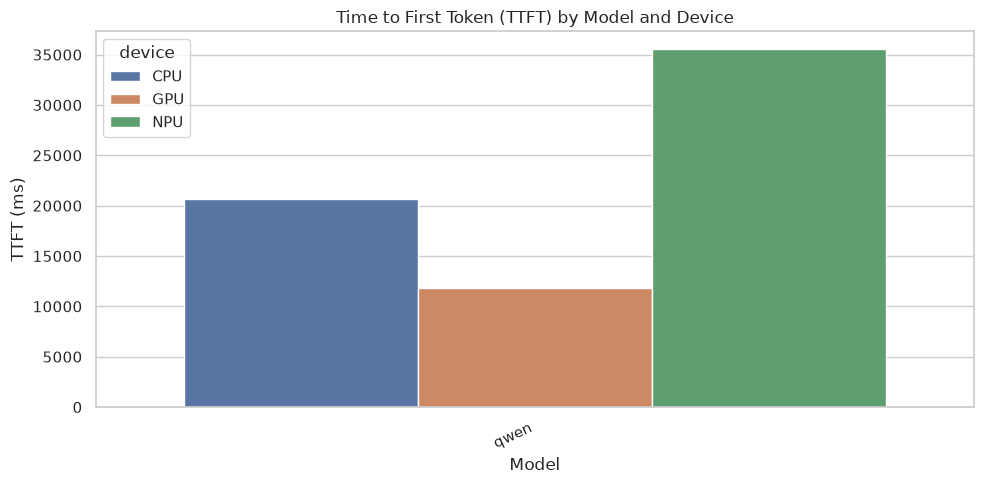

In [49]:
plot_ttft(qwen_7b)

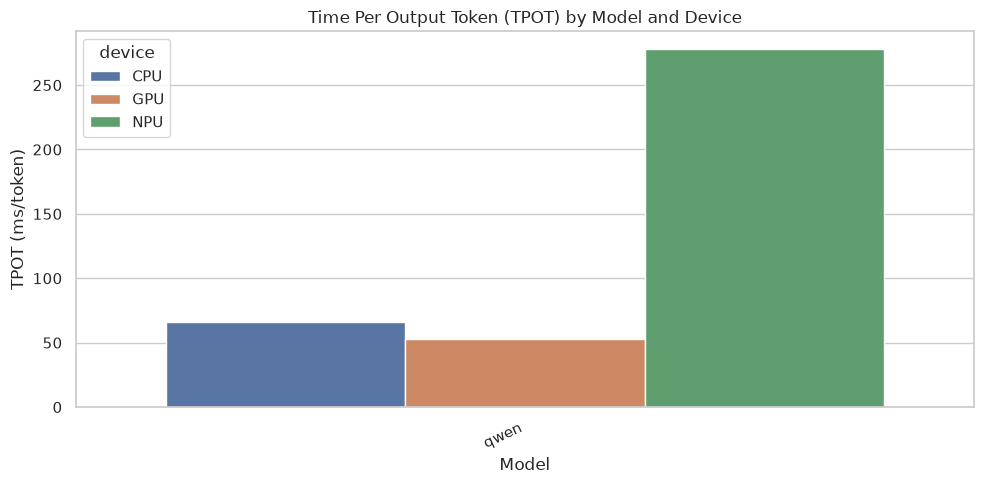

In [50]:
plot_tpot(qwen_7b)

In [51]:
data_7b.columns

Index(['iteration', 'model', 'framework', 'device', 'pretrain_time(s)',
       'initial_sys_mem(MiB)', 'initial_rss_mem(MiB)',
       'compile_max_rss_mem(MiB)', 'compile_max_sys_mem(MiB)',
       'compile_max_increase_rss_mem(MiB)',
       'compile_max_increase_sys_mem(MiB)', 'input_size', 'infer_count',
       'generation_time(s)', 'output_size', 'latency(ms)', '1st_latency(ms)',
       '2nd_avg_latency(ms)', 'precision', 'max_rss_mem(MiB)',
       'max_sys_mem(MiB)', 'max_increase_rss_mem(MiB)',
       'max_increase_sys_mem(MiB)', 'prompt_idx', 'chat_idx',
       '1st_infer_latency(ms)', '2nd_infer_avg_latency(ms)', 'num_beams',
       'batch_size', 'tokenization_time', 'detokenization_time', 'result_md5',
       'start', 'end', 'tokens_per_sec', 'source'],
      dtype='str')

In [52]:
data_7b[['device',"generation_time(s)"]]

,device,generation_time(s)
0,CPU,142.74620
1,CPU,135.31390
2,CPU,135.69324
3,CPU,136.53745
4,GPU,109.24583
5,GPU,109.11902
6,GPU,109.21213
7,GPU,109.16784
8,NPU,148.89742
9,NPU,147.84258
